In [157]:
import warnings 
warnings.filterwarnings("ignore")


In [158]:
import pandas as pd

In [159]:
cr=pd.read_csv(r"C:\Users\krish\Downloads\CreditRisk59 (1).csv")

In [160]:
cr

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0.0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1.0,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0.0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0.0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0.0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
976,LP002971,Male,Yes,4.0,Not Graduate,Yes,4009,1777.0,113.0,360.0,1.0,Urban,Y
977,LP002975,Male,Yes,0.0,Graduate,No,4158,709.0,115.0,360.0,1.0,Urban,Y
978,LP002980,Male,No,0.0,Graduate,No,3250,1993.0,126.0,360.0,NaN,Semiurban,Y
979,LP002986,Male,Yes,0.0,Graduate,No,5000,2393.0,158.0,360.0,1.0,Rural,N


In [161]:
cr.isnull().sum()[cr.isnull().sum()>0]

Gender              24
Married              3
Dependents          25
Self_Employed       55
LoanAmount          27
Loan_Amount_Term    20
Credit_History      79
dtype: int64

In [162]:
cr.Gender.fillna('Male', inplace = True)
cr. Married. fillna('Yes', inplace = True)
cr. Dependents. fillna(0, inplace = True)
cr. LoanAmount.fillna(cr.LoanAmount.mean(), inplace = True)
cr. Loan_Amount_Term.fillna(cr.Loan_Amount_Term.mean(), inplace = True)
cr. Credit_History. fillna(0, inplace = True)
cr.Self_Employed.fillna('No', inplace= True)

In [163]:
cr.select_dtypes(include='object').columns

Index(['Loan_ID', 'Gender', 'Married', 'Education', 'Self_Employed',
       'Property_Area', 'Loan_Status'],
      dtype='object')

In [164]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()

In [165]:
cr[cr.select_dtypes(include='object').columns] = cr[cr.select_dtypes(include='object').columns].apply(le.fit_transform)

In [166]:
cr

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,0,1,0,0.0,0,0,5849,0.0,142.51153,360.0,1.0,2,1
1,1,1,1,1.0,0,0,4583,1508.0,128.00000,360.0,1.0,0,0
2,2,1,1,0.0,0,1,3000,0.0,66.00000,360.0,1.0,2,1
3,3,1,1,0.0,1,0,2583,2358.0,120.00000,360.0,1.0,2,1
4,4,1,0,0.0,0,0,6000,0.0,141.00000,360.0,1.0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
976,970,1,1,4.0,1,1,4009,1777.0,113.00000,360.0,1.0,2,1
977,972,1,1,0.0,0,0,4158,709.0,115.00000,360.0,1.0,2,1
978,975,1,0,0.0,0,0,3250,1993.0,126.00000,360.0,0.0,1,1
979,978,1,1,0.0,0,0,5000,2393.0,158.00000,360.0,1.0,0,0


In [167]:
from sklearn.model_selection import train_test_split
cr_train,cr_test=train_test_split(cr,test_size=.2)

In [168]:
cr.Loan_Status.value_counts()

Loan_Status
1    712
0    269
Name: count, dtype: int64

In [169]:
cr.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,0,1,0,0.0,0,0,5849,0.0,142.51153,360.0,1.0,2,1
1,1,1,1,1.0,0,0,4583,1508.0,128.00000,360.0,1.0,0,0
2,2,1,1,0.0,0,1,3000,0.0,66.00000,360.0,1.0,2,1
3,3,1,1,0.0,1,0,2583,2358.0,120.00000,360.0,1.0,2,1
4,4,1,0,0.0,0,0,6000,0.0,141.00000,360.0,1.0,2,1


# Linear regression

In [170]:
cr

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,0,1,0,0.0,0,0,5849,0.0,142.51153,360.0,1.0,2,1
1,1,1,1,1.0,0,0,4583,1508.0,128.00000,360.0,1.0,0,0
2,2,1,1,0.0,0,1,3000,0.0,66.00000,360.0,1.0,2,1
3,3,1,1,0.0,1,0,2583,2358.0,120.00000,360.0,1.0,2,1
4,4,1,0,0.0,0,0,6000,0.0,141.00000,360.0,1.0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
976,970,1,1,4.0,1,1,4009,1777.0,113.00000,360.0,1.0,2,1
977,972,1,1,0.0,0,0,4158,709.0,115.00000,360.0,1.0,2,1
978,975,1,0,0.0,0,0,3250,1993.0,126.00000,360.0,0.0,1,1
979,978,1,1,0.0,0,0,5000,2393.0,158.00000,360.0,1.0,0,0


In [171]:
from sklearn.model_selection import train_test_split
cr_train,cr_test=train_test_split(cr,test_size=.2)

In [172]:
cr_train_x = cr_train.drop(['Loan_ID', 'Loan_Status'], axis=1)
cr_train_y = cr_train['Loan_Status']

In [173]:
cr_test_x = cr_test.drop(['Loan_ID', 'Loan_Status'], axis=1)
cr_test_y = cr_test['Loan_Status']

In [174]:
cr_test_x

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
241,1,1,1.0,1,0,2510,1983.0,140.00000,180.0,1.0,2
729,1,0,4.0,0,0,4243,4123.0,157.00000,360.0,0.0,1
378,1,0,0.0,0,0,3069,0.0,71.00000,480.0,1.0,2
952,1,1,1.0,0,1,2360,3355.0,87.00000,240.0,1.0,0
936,1,1,4.0,0,0,3400,0.0,80.00000,120.0,1.0,2
...,...,...,...,...,...,...,...,...,...,...,...
607,1,1,2.0,1,0,3987,1411.0,157.00000,360.0,1.0,0
68,1,1,4.0,1,1,7100,0.0,125.00000,60.0,1.0,2
180,1,1,1.0,0,0,6400,7250.0,180.00000,360.0,0.0,2
102,1,1,0.0,0,0,13650,0.0,142.51153,360.0,1.0,2


In [175]:
cr_train_x

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
221,1,1,2.0,0,0,4009,1717.000000,116.00000,360.0,1.0,1
496,1,1,0.0,1,0,2600,1700.000000,107.00000,360.0,1.0,0
881,0,0,1.0,1,0,3854,3575.000000,117.00000,360.0,1.0,0
908,1,1,1.0,1,0,1792,2565.000000,128.00000,360.0,1.0,2
845,1,0,0.0,0,1,2860,2988.000000,138.00000,360.0,1.0,2
...,...,...,...,...,...,...,...,...,...,...,...
242,1,0,0.0,0,0,2965,5701.000000,155.00000,60.0,1.0,2
435,0,1,0.0,0,0,10047,0.000000,142.51153,240.0,1.0,1
428,1,1,0.0,0,0,2920,16.120001,87.00000,360.0,1.0,0
815,1,1,4.0,1,0,2855,542.000000,90.00000,360.0,1.0,2


In [176]:
cr_test_y

241    0
729    1
378    0
952    1
936    1
      ..
607    1
68     1
180    0
102    1
331    1
Name: Loan_Status, Length: 197, dtype: int64

In [177]:
cr_train_y

221    1
496    1
881    1
908    1
845    1
      ..
242    1
435    1
428    1
815    1
315    1
Name: Loan_Status, Length: 784, dtype: int64

In [178]:
from sklearn.linear_model import LinearRegression
linreg=LinearRegression()

In [179]:
linreg.fit(cr_train_x,cr_train_y)

LinearRegression()

In [180]:
linreg.score(cr_train_x,cr_train_y)

0.2611781252079719

In [181]:
cr_train_x.shape[0]

784

In [182]:
cr_train_x.shape[1]

11

In [183]:
cr_train_x.shape

(784, 11)

In [184]:
cr_test_x.shape

(197, 11)

In [185]:
Rsquare=linreg.score(cr_train_x,cr_train_y)
n=cr_train_x.shape[0]
k=cr_train_x.shape[1]

adjrsquare=1-(1-Rsquare)*(n-1)/(n-k-1)
adjrsquare

0.2506508705153394

In [186]:
train_r2 = linreg.score(cr_train_x, cr_train_y)
test_r2 = linreg.score(cr_test_x, cr_test_y)

print("Train R²:", train_r2)
print("Test R²:", test_r2)

Train R²: 0.2611781252079719
Test R²: 0.29425947403166963


In [187]:
print(linreg.intercept_)

0.34035626456959994


In [188]:
linreg.coef_

array([-1.56178880e-02,  8.22208725e-02, -2.32104898e-03, -4.83995428e-02,
        3.57838327e-02,  3.39015776e-06,  2.08697641e-06, -3.79485428e-04,
       -1.49431214e-04,  5.10922697e-01,  4.69144891e-02])

In [189]:
pred_train=linreg.predict(cr_train_x)
pred_test=linreg.predict(cr_test_x)

In [190]:

err_train=cr_train_y-pred_train

In [191]:
err_train

221    0.120487
496    0.212556
881    0.277110
908    0.129951
845    0.124959
         ...   
242    0.116346
435    0.075469
428    0.158996
815    0.123112
315    0.093084
Name: Loan_Status, Length: 784, dtype: float64

In [192]:
err_train.mean()

np.float64(0.0)

In [193]:
import matplotlib.pyplot as plt
import seaborn as sns


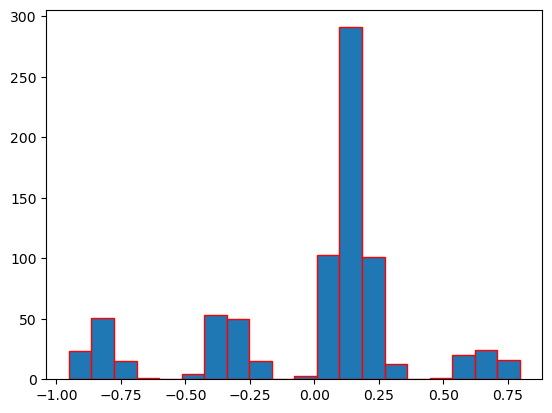

In [194]:
plt.hist(err_train,edgecolor='red',bins=20);

In [195]:
err_train.skew()

np.float64(-0.8266442578293943)

In [196]:
err_train.kurtosis()+3

np.float64(3.4476441088812777)

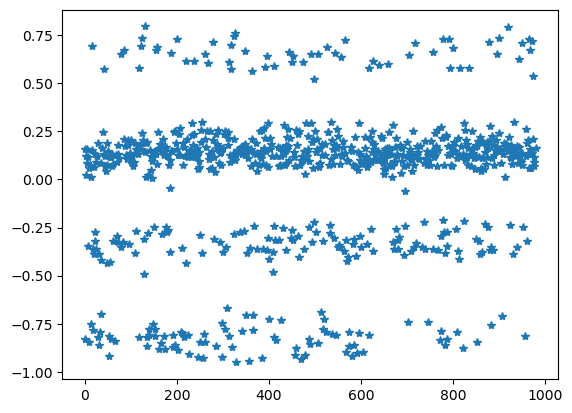

In [197]:
plt.plot(err_train,'*')

In [198]:
pred_act=pd.DataFrame()
pred_act['Actual']=cr_train_y
pred_act['Pred']=pred_train
pred_act

,Actual,Pred
221,1,0.879513
496,1,0.787444
881,1,0.722890
908,1,0.870049
845,1,0.875041
...,...,...
242,1,0.883654
435,1,0.924531
428,1,0.841004
815,1,0.876888


<Axes: xlabel='Actual', ylabel='Pred'>

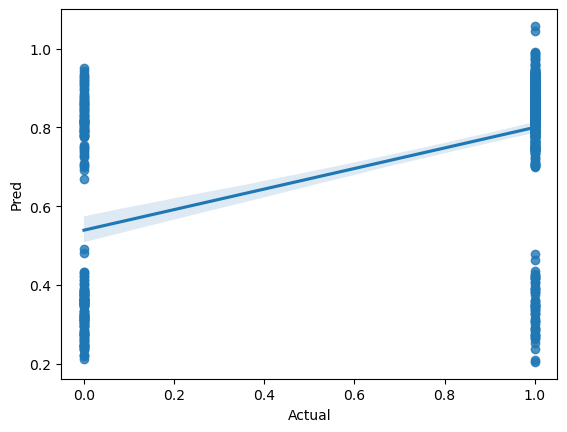

In [199]:
sns.regplot(x='Actual',y='Pred',data=pred_act)

In [200]:
err_test=cr_test_y-pred_test
err_test

241   -0.893613
729    0.728017
378   -0.841224
952    0.102531
936    0.034337
         ...   
607    0.232073
68     0.042520
180   -0.413192
102    0.049890
331    0.198459
Name: Loan_Status, Length: 197, dtype: float64

In [201]:
import numpy as np

In [202]:
mse=np.mean(np.square(err_test))
mse

np.float64(0.1451160657895663)

In [203]:
np.sqrt(mse)

np.float64(0.38094102665578866)

In [204]:
mape=np.mean(np.abs(err_test*100/cr_test_y))

In [205]:
mape

np.float64(inf)

In [206]:
#accuracy
acc=100-mape
print(acc)

-inf
